In [102]:

import os
from tqdm import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from liftover import get_lifter
sns.set_context("talk", font_scale=1.35)



# read in summary stats for caQTLs

In [6]:
icc=pd.read_csv("/data/processed/QTL_calling/atac/permissive/L2_manual/CD4T_Memory/CD4T_Memory.cis_qtl_snp.all_significant.annot.txt", sep='\t')
gate=pd.read_csv("/data/references/qtls_other/gate2018_ATAC_QTL.csv")
                

In [8]:
icc.head()

,chrom,pos,variant_id,ref,alt,info,phenotype_id,start_distance,end_distance,af,...,pval_nominal,slope,slope_se,gene_id,ICC_AF,AFR_AF,AMR_AF,EAS_AF,EUR_AF,pval_nominal_threshold
0,1,918425,rs3748591,C,T,IMPUTED;AF=0.105679;MAF=0.105679;AVG_CS=0.9865...,chr1:827284-827784,91140,90641,0.117284,...,5.416059e-07,0.534794,0.104448,NaN,0.118619,0.169014,0.020270,0.28750,0.027778,0.000009
1,1,919049,rs72902552,G,A,IMPUTED;AF=0.107901;MAF=0.107901;AVG_CS=0.9857...,chr1:827284-827784,91764,91265,0.118827,...,7.373479e-07,0.529178,0.104648,NaN,0.120120,0.176056,0.020270,0.28750,0.027778,0.000009
2,1,925474,rs57816555,T,C,IMPUTED;AF=0.895374;MAF=0.104626;AVG_CS=0.9735...,chr1:827284-827784,98189,97690,0.899691,...,1.699065e-06,-0.541743,0.110974,NaN,0.897898,0.880282,0.986486,0.71875,0.981481,0.000009
3,1,901516,rs28705752,T,C,IMPUTED;AF=0.370722;MAF=0.370722;AVG_CS=0.9681...,chr1:904498-904998,-2983,-3482,0.373457,...,5.459196e-09,-0.427325,0.071172,NaN,0.367868,0.535211,0.256757,0.41250,0.300926,0.000010
4,1,901812,rs57494724,A,G,IMPUTED;AF=0.198944;MAF=0.198944;AVG_CS=0.9757...,chr1:904498-904998,-2687,-3186,0.217593,...,4.958821e-12,-0.630405,0.087652,NaN,0.216216,0.457746,0.087838,0.31875,0.069444,0.000010


In [7]:
gate.head()

,SNP,gene,beta,chisquared,p-value
0,chr12:9436083_rs61916194,chr12:9435883-9437556,0.240566,268.769875,2.100000e-60
1,chr10:6954595_rs4748519,chr10:6954000-6955229,0.230224,190.888345,2.030000e-43
2,chr3:125709050_rs12636296,chr3:125708992-125710325,0.184427,183.861268,6.960000e-42
3,chr11:18433889_rs3740714,chr11:18433573-18434409,0.775827,156.599045,6.260000e-36
4,chr18:71915673_rs11151937,chr18:71915540-71916042,0.136314,149.863927,1.860000e-34


In [12]:
gate[['chr_pos','variant_id']]=gate['SNP'].str.split('_', expand=True)

In [13]:
gate


,SNP,gene,beta,chisquared,p-value,variant_id,rsid,chr_pos
0,chr12:9436083_rs61916194,chr12:9435883-9437556,0.240566,268.769875,2.100000e-60,rs61916194,rs61916194,chr12:9436083
1,chr10:6954595_rs4748519,chr10:6954000-6955229,0.230224,190.888345,2.030000e-43,rs4748519,rs4748519,chr10:6954595
2,chr3:125709050_rs12636296,chr3:125708992-125710325,0.184427,183.861268,6.960000e-42,rs12636296,rs12636296,chr3:125709050
3,chr11:18433889_rs3740714,chr11:18433573-18434409,0.775827,156.599045,6.260000e-36,rs3740714,rs3740714,chr11:18433889
4,chr18:71915673_rs11151937,chr18:71915540-71916042,0.136314,149.863927,1.860000e-34,rs11151937,rs11151937,chr18:71915673
...,...,...,...,...,...,...,...,...
3312,chr4:189718321_rs75910559,chr4:189717920-189718339,0.348122,8.867702,2.902603e-03,rs75910559,rs75910559,chr4:189718321
3313,chr13:101636722_rs17580898,chr13:101636615-101637080,0.628940,8.867676,2.902645e-03,rs17580898,rs17580898,chr13:101636722
3314,chr13:47242088_rs7993645,chr13:47241954-47242719,0.557818,8.866358,2.904740e-03,rs7993645,rs7993645,chr13:47242088
3315,chr6:45705659_rs829913,chr6:45704682-45706014,0.450348,8.862632,2.910676e-03,rs829913,rs829913,chr6:45705659


In [16]:
plt_df=pd.merge(icc, gate, on='variant_id',suffixes=('_icc','_gate'))

In [17]:
plt_df

,chrom,pos,variant_id,ref,alt,info,phenotype_id,start_distance,end_distance,af,...,EAS_AF,EUR_AF,pval_nominal_threshold,SNP,gene,beta,chisquared,p-value,rsid,chr_pos
0,1,1892085,rs3806168,G,C,IMPUTED;AF=0.161814;MAF=0.161814;AVG_CS=0.9939...,chr1:1693178-1693678,198906,198407,0.160494,...,0.21875,0.143519,0.000004,chr1:1823524_rs3806168,chr1:1822427-1823790,0.419004,32.342379,1.290000e-08,rs3806168,chr1:1823524
1,1,1892085,rs3806168,G,C,IMPUTED;AF=0.161814;MAF=0.161814;AVG_CS=0.9939...,chr1:1745561-1746061,146523,146024,0.160494,...,0.21875,0.143519,0.000003,chr1:1823524_rs3806168,chr1:1822427-1823790,0.419004,32.342379,1.290000e-08,rs3806168,chr1:1823524
2,1,1892085,rs3806168,G,C,IMPUTED;AF=0.161814;MAF=0.161814;AVG_CS=0.9939...,chr1:1746206-1746706,145878,145379,0.160494,...,0.21875,0.143519,0.000004,chr1:1823524_rs3806168,chr1:1822427-1823790,0.419004,32.342379,1.290000e-08,rs3806168,chr1:1823524
3,1,1892085,rs3806168,G,C,IMPUTED;AF=0.161814;MAF=0.161814;AVG_CS=0.9939...,chr1:1891485-1891985,599,100,0.160494,...,0.21875,0.143519,0.000003,chr1:1823524_rs3806168,chr1:1822427-1823790,0.419004,32.342379,1.290000e-08,rs3806168,chr1:1823524
4,1,1892085,rs3806168,G,C,IMPUTED;AF=0.161814;MAF=0.161814;AVG_CS=0.9939...,chr1:1892173-1892673,-89,-588,0.160494,...,0.21875,0.143519,0.000003,chr1:1823524_rs3806168,chr1:1822427-1823790,0.419004,32.342379,1.290000e-08,rs3806168,chr1:1823524
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1607,22,45437141,rs6007037,T,G,IMPUTED;AF=0.315478;MAF=0.315478;AVG_CS=0.9758...,chr22:45441075-45441575,-3935,-4434,0.325617,...,0.42500,0.217593,0.000002,chr22:45833021_rs6007037,chr22:45832913-45833228,0.685711,35.257974,2.890000e-09,rs6007037,chr22:45833021
1608,22,45441529,rs6007041,A,G,IMPUTED;AF=0.429877;MAF=0.429877;AVG_CS=0.9751...,chr22:45441075-45441575,453,-46,0.424383,...,0.56875,0.273148,0.000002,chr22:45837410_rs6007041,chr22:45836909-45837444,0.404637,12.249520,4.650000e-04,rs6007041,chr22:45837410
1609,22,47918714,rs5768156,G,A,TYPED;IMPUTED;AF=0.443587;MAF=0.443587;AVG_CS=...,chr22:47918473-47918973,240,-259,0.447531,...,0.68125,0.407407,0.000002,chr22:48314463_rs5768156,chr22:48314229-48314504,0.758997,66.156510,4.170000e-16,rs5768156,chr22:48314463
1610,22,49052352,rs4823981,G,T,TYPED;IMPUTED;AF=0.466297;MAF=0.466297;AVG_CS=...,chr22:49052191-49052691,160,-339,0.467593,...,0.25000,0.504630,0.000001,chr22:49448164_rs4823981,chr22:49447882-49448305,0.623354,16.561668,4.710000e-05,rs4823981,chr22:49448164


Text(0.5, 1.0, 'caQTL Beta Correlation')

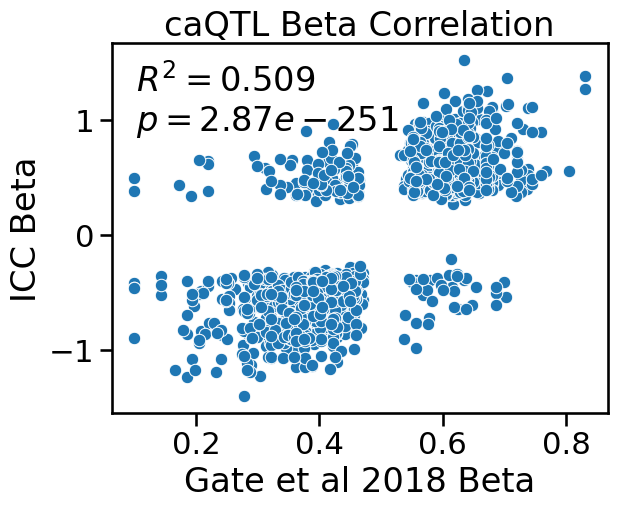

In [118]:
pthresh=5e-4
sns.scatterplot(data=plt_df[(plt_df['p-value']<pthresh) & (plt_df['pval_nominal']<pthresh) ], x='beta',y='slope')

r, p_val = stats.pearsonr(plt_df['beta'], plt_df['slope'])
r2_value = r**2
#plt.text(x=0.05, y=0.95, s=f'$R^2 = {r2_value:.3f}$', 
#         transform=plt.gca().transAxes, verticalalignment='top', fontweight='bold')

plt.text(
    x=0.05, 
    y=0.95, 
    s=f'$R^2 = {r2_value:.3f}$\n$p = {p_val:.2e}$', 
    transform=plt.gca().transAxes, 
    verticalalignment='top', 
    fontweight='bold'
)
plt.xlabel('Gate et al 2018 Beta')
plt.ylabel('ICC Beta')
plt.title('caQTL Beta Correlation')

# read in eQTL 

In [60]:
icc_eqtl=pd.read_csv("/data/processed/QTL_calling/rna/L2_manual/CD4T_Memory/CD4T_Memory.cis_qtl_snp.all_significant.annot.txt", sep='\t')
perez=pd.read_csv("/data/references/qtls_other/perez_Table6.CBC_meta_results.gz",sep='\t')
                

In [61]:
perez_t8=perez[perez['cell']=='t8']

In [62]:
icc_eqtl.head()

,chrom,pos,variant_id,ref,alt,info,phenotype_id,start_distance,end_distance,af,...,pval_nominal,slope,slope_se,gene_id,ICC_AF,AFR_AF,AMR_AF,EAS_AF,EUR_AF,pval_nominal_threshold
0,1,995153,rs3128110,C,A,IMPUTED;AF=1.47059e-05;MAF=1.47059e-05;AVG_CS=...,ENSG00000187608,-5985,-18344,0.357362,...,2.147230e-08,0.298903,0.051977,ISG15,NaN,NaN,NaN,NaN,NaN,0.000028
1,1,995153,rs3128110,C,G,IMPUTED;AF=0.342427;MAF=0.342427;AVG_CS=0.9623...,ENSG00000187608,-5985,-18344,0.357362,...,2.147230e-08,0.298903,0.051977,ISG15,0.352853,0.514085,0.222973,0.25000,0.412037,0.000028
2,1,995187,rs3121574,A,G,IMPUTED;AF=0.345256;MAF=0.345256;AVG_CS=0.9619...,ENSG00000187608,-5951,-18310,0.360429,...,2.361664e-08,0.296849,0.051781,ISG15,0.355856,0.521127,0.222973,0.25625,0.412037,0.000028
3,1,995371,rs3128111,C,G,IMPUTED;AF=0.298588;MAF=0.298588;AVG_CS=0.9688...,ENSG00000187608,-5767,-18126,0.311350,...,1.018907e-07,0.291159,0.053393,ISG15,0.304805,0.373239,0.209459,0.18750,0.412037,0.000028
4,1,995512,rs2799059,T,C,IMPUTED;AF=0.362292;MAF=0.362292;AVG_CS=0.9596...,ENSG00000187608,-5626,-17985,0.375767,...,1.532283e-07,0.279498,0.052018,ISG15,0.372372,0.577465,0.229730,0.26250,0.416667,0.000028


In [63]:
icc_eqtl.columns

Index(['chrom', 'pos', 'variant_id', 'ref', 'alt', 'info', 'phenotype_id',
       'start_distance', 'end_distance', 'af', 'ma_samples', 'ma_count',
       'pval_nominal', 'slope', 'slope_se', 'gene_id', 'ICC_AF', 'AFR_AF',
       'AMR_AF', 'EAS_AF', 'EUR_AF', 'pval_nominal_threshold'],
      dtype='object')

In [64]:
perez_t8.head()

,cell,RSID,PVALUE_FE,BETA_FE,STD_FE
21717352,t8,10:100044928_PYROXD2,0.239103,-0.105490,0.089608
21717353,t8,10:100045000_PYROXD2,0.017710,-0.171848,0.072460
21717354,t8,10:100045147_PYROXD2,0.013509,-0.175150,0.070909
21717355,t8,10:100045166_PYROXD2,0.297009,0.132585,0.127135
21717356,t8,10:100045813_PYROXD2,0.302291,-0.130575,0.126583


In [65]:
perez_t8[['chr_pos','gene']]=perez_t8['RSID'].str.split('_', expand=True)


/tmp/ipykernel_5307/2316867736.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  perez_t8[['chr_pos','gene']]=perez_t8['RSID'].str.split('_', expand=True)
/tmp/ipykernel_5307/2316867736.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  perez_t8[['chr_pos','gene']]=perez_t8['RSID'].str.split('_', expand=True)


In [66]:
perez_t8[['chr','pos']]=perez_t8['chr_pos'].str.split(':', expand=True)

/tmp/ipykernel_5307/3640352536.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  perez_t8[['chr','pos']]=perez_t8['chr_pos'].str.split(':', expand=True)
/tmp/ipykernel_5307/3640352536.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  perez_t8[['chr','pos']]=perez_t8['chr_pos'].str.split(':', expand=True)


In [29]:
from liftover import get_lifter

# This first call downloads the chain file automatically if you don't have it
converter = get_lifter('hg19','hg38')



In [30]:
# Now you can convert coordinates instantly
# Format: converter[chromosome][position]
new_pos = converter['chr1'][1000000]

print(new_pos)

[('chr1', 1064620, '+')]


In [55]:
converter['10'][100044928][0][1]

98285171

In [83]:
perez_t8['hg_38_pos']=[ int(converter[f"chr{chr}"][int(pos)][0][1]) if converter[f"chr{chr}"][int(pos)] else None for chr, pos in zip(perez_t8['chr'].tolist(),perez_t8['pos'].tolist() ) ]




/tmp/ipykernel_5307/2057334996.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  perez_t8['hg_38_pos']=[ int(converter[f"chr{chr}"][int(pos)][0][1]) if converter[f"chr{chr}"][int(pos)] else None for chr, pos in zip(perez_t8['chr'].tolist(),perez_t8['pos'].tolist() ) ]


In [85]:
perez_t8

,cell,RSID,PVALUE_FE,BETA_FE,STD_FE,chr_pos,gene,chr,pos,hg_38_pos
21717352,t8,10:100044928_PYROXD2,0.239103,-0.105490,0.089608,10:100044928,PYROXD2,10,100044928,98285171.0
21717353,t8,10:100045000_PYROXD2,0.017710,-0.171848,0.072460,10:100045000,PYROXD2,10,100045000,98285243.0
21717354,t8,10:100045147_PYROXD2,0.013509,-0.175150,0.070909,10:100045147,PYROXD2,10,100045147,98285390.0
21717355,t8,10:100045166_PYROXD2,0.297009,0.132585,0.127135,10:100045166,PYROXD2,10,100045166,98285409.0
21717356,t8,10:100045813_PYROXD2,0.302291,-0.130575,0.126583,10:100045813,PYROXD2,10,100045813,98286056.0
...,...,...,...,...,...,...,...,...,...,...
24437149,t8,9:99802796_HIATL2,0.418315,0.079918,0.098744,9:99802796,HIATL2,9,99802796,97040514.0
24437150,t8,9:99804997_HIATL2,0.643367,-0.054813,0.118387,9:99804997,HIATL2,9,99804997,97042715.0
24437151,t8,9:99805079_HIATL2,0.418315,0.079918,0.098744,9:99805079,HIATL2,9,99805079,97042797.0
24437152,t8,9:99806169_HIATL2,0.418315,0.079918,0.098744,9:99806169,HIATL2,9,99806169,97043887.0


In [86]:
icc_eqtl

,chrom,pos,variant_id,ref,alt,info,phenotype_id,start_distance,end_distance,af,...,pval_nominal,slope,slope_se,gene_id,ICC_AF,AFR_AF,AMR_AF,EAS_AF,EUR_AF,pval_nominal_threshold
0,1,995153,rs3128110,C,A,IMPUTED;AF=1.47059e-05;MAF=1.47059e-05;AVG_CS=...,ENSG00000187608,-5985,-18344,0.357362,...,2.147230e-08,0.298903,0.051977,ISG15,NaN,NaN,NaN,NaN,NaN,0.000028
1,1,995153,rs3128110,C,G,IMPUTED;AF=0.342427;MAF=0.342427;AVG_CS=0.9623...,ENSG00000187608,-5985,-18344,0.357362,...,2.147230e-08,0.298903,0.051977,ISG15,0.352853,0.514085,0.222973,0.25000,0.412037,0.000028
2,1,995187,rs3121574,A,G,IMPUTED;AF=0.345256;MAF=0.345256;AVG_CS=0.9619...,ENSG00000187608,-5951,-18310,0.360429,...,2.361664e-08,0.296849,0.051781,ISG15,0.355856,0.521127,0.222973,0.25625,0.412037,0.000028
3,1,995371,rs3128111,C,G,IMPUTED;AF=0.298588;MAF=0.298588;AVG_CS=0.9688...,ENSG00000187608,-5767,-18126,0.311350,...,1.018907e-07,0.291159,0.053393,ISG15,0.304805,0.373239,0.209459,0.18750,0.412037,0.000028
4,1,995512,rs2799059,T,C,IMPUTED;AF=0.362292;MAF=0.362292;AVG_CS=0.9596...,ENSG00000187608,-5626,-17985,0.375767,...,1.532283e-07,0.279498,0.052018,ISG15,0.372372,0.577465,0.229730,0.26250,0.416667,0.000028
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161891,22,50536801,rs58661495,CT,C,IMPUTED;AF=0.116564;MAF=0.116564;AVG_CS=0.9755...,ENSG00000008735,-63992,-63992,0.122699,...,2.853993e-06,0.374531,0.078521,MAPK8IP2,0.121622,0.070422,0.128378,0.23125,0.069444,0.000028
161892,22,50537216,rs5770864,G,A,IMPUTED;AF=0.188689;MAF=0.188689;AVG_CS=0.9760...,ENSG00000008735,-63577,-63577,0.199386,...,1.185713e-05,0.288919,0.064878,MAPK8IP2,0.199700,0.309859,0.155405,0.26250,0.111111,0.000028
161893,22,50538738,rs5770769,A,T,IMPUTED;AF=0.143051;MAF=0.143051;AVG_CS=0.9724...,ENSG00000008735,-62055,-62055,0.142638,...,8.521104e-07,0.361428,0.071911,MAPK8IP2,0.142643,0.105634,0.141892,0.23750,0.097222,0.000028
161894,22,50539833,rs5770871,G,A,IMPUTED;AF=0.133872;MAF=0.133872;AVG_CS=0.9751...,ENSG00000008735,-60960,-60960,0.133436,...,2.303643e-05,0.322879,0.075100,MAPK8IP2,0.133634,0.084507,0.141892,0.23125,0.087963,0.000028


In [92]:
perez_t8['chr'] = perez_t8['chr'].astype(str)
icc_eqtl['chrom'] = icc_eqtl['chrom'].astype(str)
merged_df = pd.merge(
    perez_t8, 
    icc_eqtl, 
    left_on=['chr','hg_38_pos','gene'], 
    right_on=['chrom','pos','gene_id'],
    how='inner'
)

/tmp/ipykernel_5307/2327594537.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  perez_t8['chr'] = perez_t8['chr'].astype(str)


In [93]:
merged_df

,cell,RSID,PVALUE_FE,BETA_FE,STD_FE,chr_pos,gene,chr,pos_x,hg_38_pos,...,pval_nominal,slope,slope_se,gene_id,ICC_AF,AFR_AF,AMR_AF,EAS_AF,EUR_AF,pval_nominal_threshold
0,t8,10:111703389_ADD3,0.032598,0.086225,0.040349,10:111703389,ADD3,10,111703389,109943631.0,...,2.623862e-05,0.155152,0.036347,ADD3,0.325826,0.563380,0.195946,0.41875,0.189815,0.000028
1,t8,10:111706856_ADD3,0.032598,0.086225,0.040349,10:111706856,ADD3,10,111706856,109947098.0,...,5.187516e-06,0.181244,0.039069,ADD3,0.288288,0.507042,0.168919,0.37500,0.162037,0.000028
2,t8,10:111707255_ADD3,0.051396,0.078256,0.040169,10:111707255,ADD3,10,111707255,109947497.0,...,3.768017e-06,0.182918,0.038841,ADD3,0.286787,0.500000,0.168919,0.37500,0.162037,0.000028
3,t8,10:111710817_ADD3,0.051396,0.078256,0.040169,10:111710817,ADD3,10,111710817,109951059.0,...,4.016390e-06,0.181560,0.038667,ADD3,0.291291,0.514085,0.168919,0.38125,0.162037,0.000028
4,t8,10:111712902_ADD3,0.022289,0.091355,0.039973,10:111712902,ADD3,10,111712902,109953144.0,...,4.016390e-06,0.181560,0.038667,ADD3,0.291291,0.514085,0.168919,0.38125,0.162037,0.000028
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46189,t8,9:98714578_ERCC6L2,0.482866,-0.084152,0.119925,9:98714578,ERCC6L2,9,98714578,95952296.0,...,3.222604e-10,0.481907,0.074126,ERCC6L2,0.141141,0.091549,0.195946,0.18750,0.101852,0.000027
46190,t8,9:98718851_ERCC6L2,0.482866,-0.084152,0.119925,9:98718851,ERCC6L2,9,98718851,95956569.0,...,3.222604e-10,0.481907,0.074126,ERCC6L2,0.141141,0.091549,0.195946,0.18750,0.101852,0.000027
46191,t8,9:98727564_ERCC6L2,0.482866,-0.084152,0.119925,9:98727564,ERCC6L2,9,98727564,95965282.0,...,3.222604e-10,0.481907,0.074126,ERCC6L2,0.141141,0.091549,0.195946,0.18750,0.101852,0.000027
46192,t8,9:98728666_ERCC6L2,0.482866,-0.084152,0.119925,9:98728666,ERCC6L2,9,98728666,95966384.0,...,6.873331e-11,0.501700,0.074195,ERCC6L2,0.136637,0.091549,0.195946,0.16875,0.101852,0.000027


Text(0.5, 1.0, 'eQTL Beta Correlation')

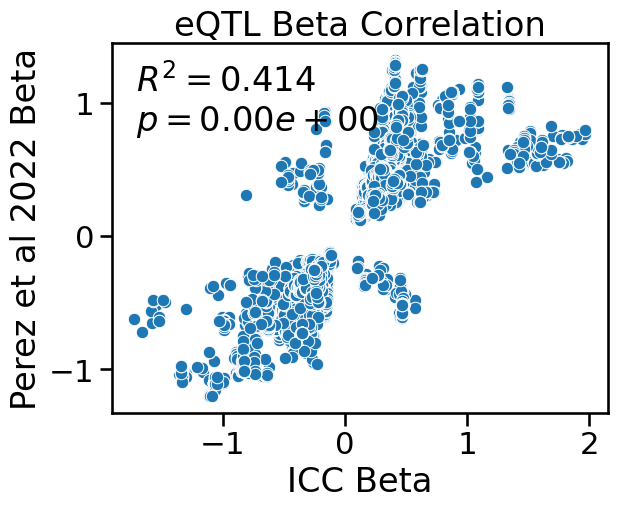

In [120]:
pthresh=5e-4
sns.scatterplot(data=merged_df[(merged_df['PVALUE_FE']<pthresh) & (merged_df['pval_nominal']<pthresh) ], x='BETA_FE',y='slope')

r, p_val = stats.pearsonr(merged_df['BETA_FE'], merged_df['slope'])
r2_value = r**2
plt.text(
    x=0.05, 
    y=0.95, 
    s=f'$R^2 = {r2_value:.3f}$\n$p = {p_val:.2e}$', 
    transform=plt.gca().transAxes, 
    verticalalignment='top', 
    fontweight='bold'
)
plt.ylabel('Perez et al 2022 Beta')
plt.xlabel('ICC Beta')
plt.title('eQTL Beta Correlation')